In [5]:
import pandas as pd

Overview

In [6]:
df = pd.read_csv(
    "../data/consumption.csv",
    sep=";",
    decimal=",",
    parse_dates=["STARTTID", "SLUTTID"]
)

In [7]:
print("Antall rader og kolonner:", df.shape)
print("\nKolonnenavn og datatyper:")
print(df.dtypes)

print("\nFørste rader:")
print(df.head())

print("\nManglende verdier per kolonne:")
print(df.isnull().sum())

print("\nAntall unike kommuner:", df["KOMMUNE"].nunique())
print("Forbruksgrupper:", df["FORBRUKSGRUPPE"].unique())

print("\nTidsperiode:")
print("Fra:", df["STARTTID"].min())
print("Til:", df["STARTTID"].max())

print("\nDeskriptiv statistikk for volum (kWh):")
print(df["VOLUM_KWH"].describe())

print("\nAntall målepunkter, deskriptiv statistikk:")
print(df["ANTALL_MÅLEPUNKT"].describe())

Antall rader og kolonner: (39951726, 7)

Kolonnenavn og datatyper:
STARTTID             object
SLUTTID              object
KOMMUNE              object
KOMMUNENUMMER         int64
FORBRUKSGRUPPE       object
VOLUM_KWH           float64
ANTALL_MÅLEPUNKT      int64
dtype: object

Første rader:
                    STARTTID                    SLUTTID    KOMMUNE  \
0  2022-02-01 00:00:00+01:00  2022-02-01 01:00:00+01:00   Aarborte   
1  2022-02-01 00:00:00+01:00  2022-02-01 01:00:00+01:00   Aarborte   
2  2022-02-01 00:00:00+01:00  2022-02-01 01:00:00+01:00   Aarborte   
3  2022-02-01 00:00:00+01:00  2022-02-01 01:00:00+01:00  Alstahaug   
4  2022-02-01 00:00:00+01:00  2022-02-01 01:00:00+01:00  Alstahaug   

   KOMMUNENUMMER FORBRUKSGRUPPE  VOLUM_KWH  ANTALL_MÅLEPUNKT  
0           1826     Forretning    481.204                47  
1           1826       Industri   1017.999                20  
2           1826         Privat   1417.728               559  
3           1820     Forretning   6

Endre tiden og filtrere

In [8]:
df["STARTTID"] = pd.to_datetime(
    df["STARTTID"],
    utc=True
)

df["SLUTTID"] = pd.to_datetime(
    df["SLUTTID"],
    utc=True
)

df["STARTTID"] = df["STARTTID"].dt.tz_convert("Europe/Oslo")
df["SLUTTID"] = df["SLUTTID"].dt.tz_convert("Europe/Oslo")

df["YEAR"] = df["STARTTID"].dt.year
df["MONTH"] = df["STARTTID"].dt.month
df["DAY"] = df["STARTTID"].dt.day
df["HOUR"] = df["STARTTID"].dt.hour
df["DAY_OF_WEEK"] = df["STARTTID"].dt.dayofweek

In [9]:
df[["STARTTID", "SLUTTID"]].head()

,STARTTID,SLUTTID
0,2022-02-01 00:00:00+01:00,2022-02-01 01:00:00+01:00
1,2022-02-01 00:00:00+01:00,2022-02-01 01:00:00+01:00
2,2022-02-01 00:00:00+01:00,2022-02-01 01:00:00+01:00
3,2022-02-01 00:00:00+01:00,2022-02-01 01:00:00+01:00
4,2022-02-01 00:00:00+01:00,2022-02-01 01:00:00+01:00


In [10]:
df[["STARTTID", "SLUTTID"]].dtypes

STARTTID    datetime64[ns, Europe/Oslo]
SLUTTID     datetime64[ns, Europe/Oslo]
dtype: object

In [11]:
df[
    ["STARTTID", "YEAR", "MONTH", "DAY", "HOUR", "DAY_OF_WEEK"]
].head()

,STARTTID,YEAR,MONTH,DAY,HOUR,DAY_OF_WEEK
0,2022-02-01 00:00:00+01:00,2022,2,1,0,1
1,2022-02-01 00:00:00+01:00,2022,2,1,0,1
2,2022-02-01 00:00:00+01:00,2022,2,1,0,1
3,2022-02-01 00:00:00+01:00,2022,2,1,0,1
4,2022-02-01 00:00:00+01:00,2022,2,1,0,1


Lage subset siden datamengden er så stor

In [12]:
df_subset = df[
    (df["KOMMUNE"] == "Oslo") &
    (df["FORBRUKSGRUPPE"] == "Privat")
].copy()

In [13]:
df_subset.shape

(37199, 12)

In [14]:
df_subset.head()

,STARTTID,SLUTTID,KOMMUNE,KOMMUNENUMMER,FORBRUKSGRUPPE,VOLUM_KWH,ANTALL_MÅLEPUNKT,YEAR,MONTH,DAY,HOUR,DAY_OF_WEEK
647,2022-02-01 00:00:00+01:00,2022-02-01 01:00:00+01:00,Oslo,301,Privat,608573.168,344956,2022,2,1,0,1
1721,2022-02-01 01:00:00+01:00,2022-02-01 02:00:00+01:00,Oslo,301,Privat,578991.082,344956,2022,2,1,1,1
2795,2022-02-01 02:00:00+01:00,2022-02-01 03:00:00+01:00,Oslo,301,Privat,568405.226,344956,2022,2,1,2,1
3869,2022-02-01 03:00:00+01:00,2022-02-01 04:00:00+01:00,Oslo,301,Privat,563256.685,344956,2022,2,1,3,1
4943,2022-02-01 04:00:00+01:00,2022-02-01 05:00:00+01:00,Oslo,301,Privat,561023.406,344956,2022,2,1,4,1


In [15]:
df_subset["KWH_PER_POINT"] = (
    df_subset["VOLUM_KWH"] / df_subset["ANTALL_MÅLEPUNKT"]
)

In [16]:
df_subset[
    ["STARTTID", "VOLUM_KWH", "ANTALL_MÅLEPUNKT", "KWH_PER_POINT"]
].head()

,STARTTID,VOLUM_KWH,ANTALL_MÅLEPUNKT,KWH_PER_POINT
647,2022-02-01 00:00:00+01:00,608573.168,344956,1.764205
1721,2022-02-01 01:00:00+01:00,578991.082,344956,1.678449
2795,2022-02-01 02:00:00+01:00,568405.226,344956,1.647762
3869,2022-02-01 03:00:00+01:00,563256.685,344956,1.632836
4943,2022-02-01 04:00:00+01:00,561023.406,344956,1.626362


In [17]:
hourly_avg = (
    df_subset
    .groupby("HOUR")["KWH_PER_POINT"]
    .mean()
)

hourly_avg

HOUR
0     1.205479
1     1.129436
2     1.084183
3     1.061139
4     1.050158
5     1.061773
6     1.140179
7     1.266415
8     1.301723
9     1.306933
10    1.310753
11    1.311818
12    1.301861
13    1.288617
14    1.288596
15    1.319189
16    1.403052
17    1.478342
18    1.512064
19    1.515590
20    1.503164
21    1.472863
22    1.411872
23    1.313103
Name: KWH_PER_POINT, dtype: float64

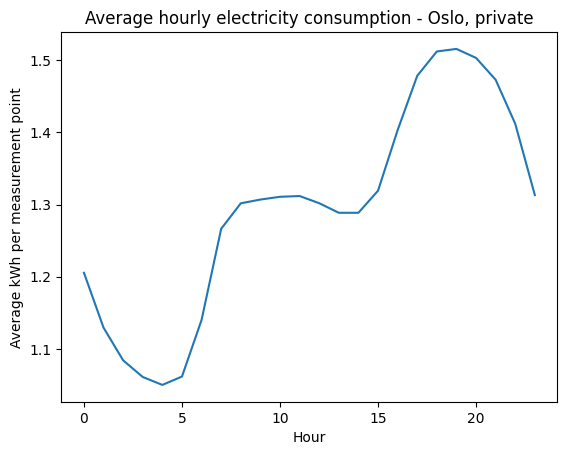

In [18]:
import matplotlib.pyplot as plt

hourly_avg.plot()
plt.xlabel("Hour")
plt.ylabel("Average kWh per measurement point")
plt.title("Average hourly electricity consumption - Oslo, private")
plt.show()

In [19]:
from sklearn.linear_model import LinearRegression
import numpy as np

X = hourly_avg.index.values.reshape(-1, 1)
y = hourly_avg.values

linear_model = LinearRegression()
linear_model.fit(X, y)

y_pred = linear_model.predict(X)

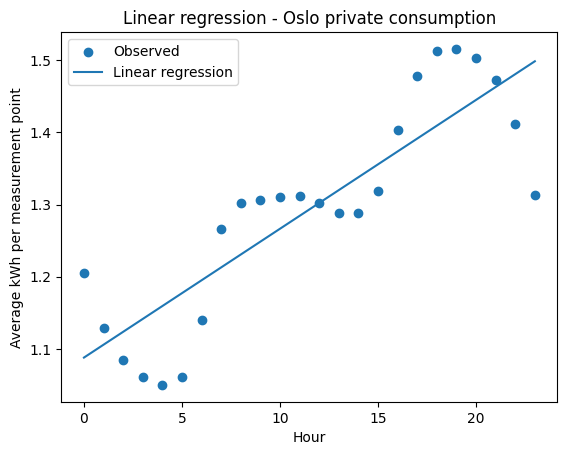

In [20]:
plt.scatter(X, y, label="Observed")
plt.plot(X, y_pred, label="Linear regression")

plt.xlabel("Hour")
plt.ylabel("Average kWh per measurement point")
plt.title("Linear regression - Oslo private consumption")
plt.legend()
plt.show()

In [21]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)

X_poly = poly.fit_transform(X)

poly_model = LinearRegression()
poly_model.fit(X_poly, y)

y_poly_pred = poly_model.predict(X_poly)

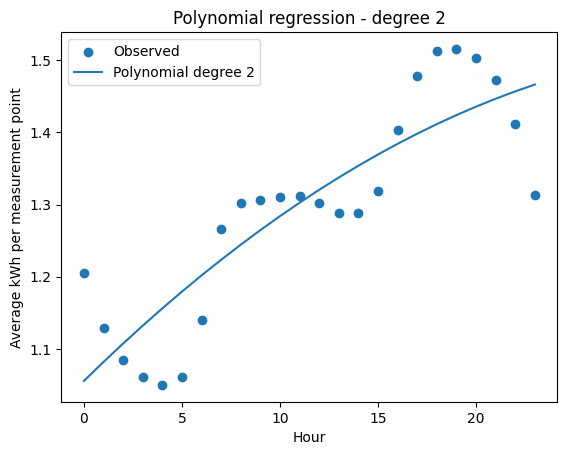

In [22]:
plt.scatter(X, y, label="Observed")
plt.plot(X, y_poly_pred, label="Polynomial degree 2")

plt.xlabel("Hour")
plt.ylabel("Average kWh per measurement point")
plt.title("Polynomial regression - degree 2")
plt.legend()
plt.show()

In [23]:
poly = PolynomialFeatures(degree=3, include_bias=False)

X_poly = poly.fit_transform(X)

poly_model = LinearRegression()
poly_model.fit(X_poly, y)

y_poly_pred = poly_model.predict(X_poly)

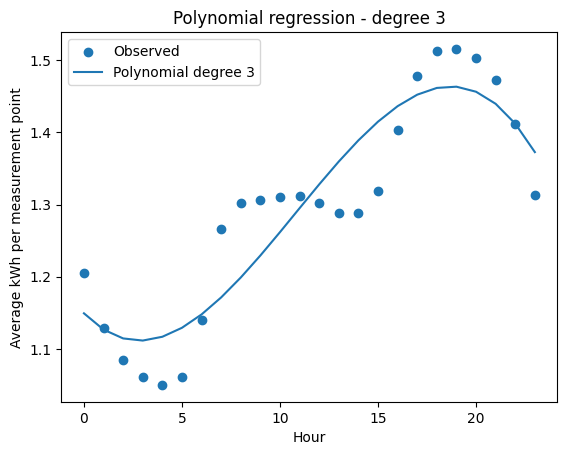

In [24]:
plt.scatter(X, y, label="Observed")
plt.plot(X, y_poly_pred, label="Polynomial degree 3")

plt.xlabel("Hour")
plt.ylabel("Average kWh per measurement point")
plt.title("Polynomial regression - degree 3")
plt.legend()
plt.show()

In [25]:
from sklearn.metrics import mean_squared_error

# Degree 2
poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_poly2 = poly2.fit_transform(X)

poly2_model = LinearRegression()
poly2_model.fit(X_poly2, y)

y_poly2_pred = poly2_model.predict(X_poly2)

# Degree 3
poly3 = PolynomialFeatures(degree=3, include_bias=False)
X_poly3 = poly3.fit_transform(X)

poly3_model = LinearRegression()
poly3_model.fit(X_poly3, y)

y_poly3_pred = poly3_model.predict(X_poly3)

mse_linear = mean_squared_error(y, y_pred)
mse_poly2 = mean_squared_error(y, y_poly2_pred)
mse_poly3 = mean_squared_error(y, y_poly3_pred)

print("Linear:", mse_linear)
print("Degree 2:", mse_poly2)
print("Degree 3:", mse_poly3)

Linear: 0.0057847988650815835
Degree 2: 0.005517240529407758
Degree 3: 0.0034516416998503657
